# Pre-entrega 4 · Parte 1 — Datos, modelo base y configuración LoRA
**Data Science III · Módulo 4: Deep Learning aplicado a NLP** — Elizabeth Luque

Clasificación de AG News (4 clases) con un Transformer ajustado mediante **LoRA (PEFT)**, comparado contra el baseline TF-IDF + Naive Bayes de la Pre-entrega 3.

El trabajo está dividido en tres partes, siguiendo los cinco pasos de la práctica en vivo:

| Parte | Pasos | Contenido | Hardware |
|---|---|---|---|
| **1 (este notebook)** | 1 · 2 · 3 | Dataset en formato Hugging Face, elección justificada del modelo base, configuración de LoRA y auditoría de parámetros | CPU alcanza |
| 2 | 4 | Fine-tuning con `Trainer`, curvas train vs. validación, tiempo de GPU y ablación de `r` y learning rate | GPU T4 (Colab) |
| 3 | 5 | Benchmark en test contra el Módulo 3, matrices de confusión y reporte PDF | GPU T4 (Colab) |

## 0. Setup
En Colab: `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`, y después descomentar la primera celda.

In [1]:
# !git clone https://github.com/scarletluque0805/ds3-transformer-lora.git && %cd ds3-transformer-lora
# !pip install -q -r requirements.txt
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import transformers, peft, datasets
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 120)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | datasets {datasets.__version__}")
print(f"¿GPU disponible?: {torch.cuda.is_available()}" + (f" -> {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else
      " -> Parte 1 no entrena: alcanza con CPU. El fine-tuning (Parte 2) se ejecuta en Colab con GPU T4."))

torch 2.15.0+cu132 | transformers 5.22.2 | peft 0.21.2 | datasets 5.1.0
¿GPU disponible?: False -> Parte 1 no entrena: alcanza con CPU. El fine-tuning (Parte 2) se ejecuta en Colab con GPU T4.


## Paso 1 · Dataset en formato Hugging Face
- Se carga con el **`cargar_dataset.py` de la cátedra** (mismo corpus que en los Módulos 2 y 3).
- La columna `label` (texto) pasa a **entero** con el mismo criterio que sugiere el loader: clases en orden alfabético → 0..3. El `Trainer` espera esa columna con el nombre `labels`.
- **Splits:** `train` 90% / `validation` 10% (estratificados, del `ag_news_train.csv`) y `test` = el `ag_news_test.csv` completo. **El test es exactamente el mismo que usó el baseline del Módulo 3**, así el benchmark final es justo, y no se toca hasta la Parte 3.

In [2]:
from src import datos_hf as dh
tr, va, te, label2id, id2label = dh.preparar_dataframes()
hf_ds = dh.a_datasetdict(tr, va, te)
print(hf_ds)
print("\nMapeo de etiquetas (label2id):", label2id)
pd.DataFrame({s: d.label.value_counts().sort_index() for s, d in [("train", tr), ("validation", va), ("test", te)]}).assign(
    labels=lambda x: x.index.map(label2id))[["labels", "train", "validation", "test"]]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 7200
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 800
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 2000
    })
})

Mapeo de etiquetas (label2id): {'Business': 0, 'Sci_Tech': 1, 'Sports': 2, 'World': 3}


,labels,train,validation,test
label,,,,
Business,0,1800,200,500
Sci_Tech,1,1800,200,500
Sports,2,1800,200,500
World,3,1800,200,500


In [3]:
# Controles: tipos, nulos, solapamientos entre splits
pd.DataFrame({
    "dtype labels": [str(hf_ds[s].features["labels"].dtype) for s in hf_ds],
    "nulos": [int(d.text.isna().sum()) for d in (tr, va, te)],
    "textos vacíos": [int((d.text.str.len() == 0).sum()) for d in (tr, va, te)],
    "solapamiento con train": ["—", int(va.text.isin(tr.text).sum()), int(te.text.isin(tr.text).sum())],
}, index=list(hf_ds))

,dtype labels,nulos,textos vacíos,solapamiento con train
train,int64,0,0,—
validation,int64,0,0,0
test,int64,0,0,1


En el CSV original no hay ningún texto de test repetido en train. Después de la limpieza aparece **1 caso de 2.000**: la misma noticia de Reuters ("Exporters Lead Nikkei Up, Trade Slow", Business) está en train con el dateline `TOKYO (Reuters) -` y en test sin él. Es un **casi-duplicado propio del dataset**, no una fuga creada por el pipeline. Se deja en el test para que sea **idéntico al del baseline del Módulo 3** (el baseline también lo vio). Su efecto máximo sobre cualquier métrica es de 0,05 puntos.

### ¿Qué texto recibe el Transformer?
En el Módulo 2 se generaron tres versiones del corpus. Para el Transformer se usa **solo la limpieza estructural** (`clean_text`: HTML, entidades rotas, URLs, firmas de agencia, datelines y tickers), **sin lematizar, sin pasar a minúsculas y sin quitar stop-words**:
- El modelo fue **preentrenado con texto natural**. Las preposiciones, las negaciones y el orden son el contexto que aprovecha la auto-atención, y lematizar ("rising" → "rise") rompería la distribución que conoce.
- La limpieza estructural sí hace falta: en el Módulo 3 comprobamos que los restos de URLs y las firmas de agencia son **atajos** (*shortcut learning*), y un Transformer los aprendería igual o mejor.
- Las minúsculas las aplica el propio tokenizer (`uncased`).

In [4]:
from cargar_dataset import cargar
crudo_tr, _ = cargar("ag_news")
idx = crudo_tr.text.str.contains("HREF").idxmax()
pd.DataFrame({"texto": [crudo_tr.text[idx][:230], dh.clean_text(crudo_tr.text[idx])[:230]]}, index=["crudo (CSV)", "entrada al Transformer"])

,texto
crudo (CSV),"PepsiCo Says Profit Rises on Tax Benefits. NEW YORK (Reuters) - PepsiCo Inc. &lt;A HREF=""http://www.investor.reuters..."
entrada al Transformer,"PepsiCo Says Profit Rises on Tax Benefits. PepsiCo Inc. , the world's No. 2 soft drink company, said on Thursday qua..."


### Tokenización: sub-tokens, attention mask y `max_length`
El tokenizer de `distilbert-base-uncased` (WordPiece, 30.522 sub-tokens) resuelve lo visto en clase: **sub-tokens**, **padding**, **truncation** y **attention mask**.

In [5]:
from transformers import AutoTokenizer, BertTokenizerFast
CKPT = "distilbert-base-uncased"
try:
    tokenizer = AutoTokenizer.from_pretrained(CKPT); origen_tok = "Hub"
except Exception:   # sin acceso al Hub: mismo vocabulario WordPiece (idéntico al de bert-base-uncased)
    tokenizer = BertTokenizerFast(str(ROOT / "assets" / "vocab_bert_uncased.txt"), do_lower_case=True); origen_tok = "vocabulario local idéntico"
print(f"Tokenizer {CKPT} ({origen_tok}) | vocabulario: {tokenizer.vocab_size:,} sub-tokens")

ejemplos = ["Oracle completes hostile takeover of PeopleSoft", "Yankees win"]
lote = tokenizer(ejemplos, padding=True, truncation=True, max_length=72)
for i, t in enumerate(ejemplos):
    print(f"\n'{t}'")
    print("  sub-tokens     :", tokenizer.convert_ids_to_tokens(lote["input_ids"][i]))
    print("  attention_mask :", lote["attention_mask"][i], " (0 = padding, la atención lo ignora)")

Tokenizer distilbert-base-uncased (vocabulario local idéntico) | vocabulario: 30,522 sub-tokens

'Oracle completes hostile takeover of PeopleSoft'
  sub-tokens     : ['[CLS]', 'oracle', 'completes', 'hostile', 'takeover', 'of', 'peoples', '##oft', '[SEP]']
  attention_mask : [1, 1, 1, 1, 1, 1, 1, 1, 1]  (0 = padding, la atención lo ignora)

'Yankees win'
  sub-tokens     : ['[CLS]', 'yankees', 'win', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
  attention_mask : [1, 1, 1, 1, 0, 0, 0, 0, 0]  (0 = padding, la atención lo ignora)


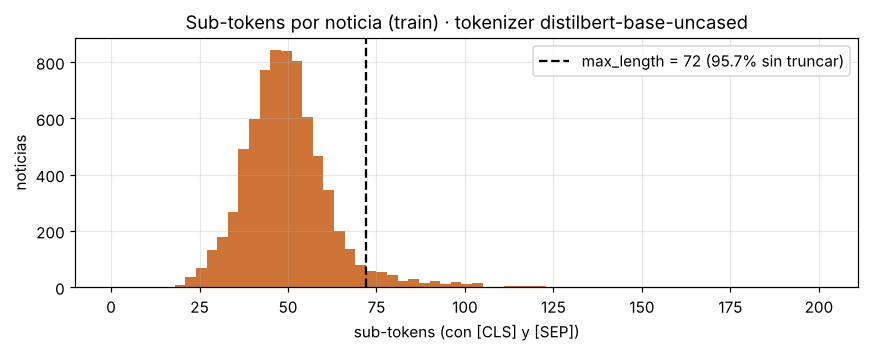

,valor
mediana,48.0
p95,70.0
p99,95.0
máximo,199.0
max_length elegido,72.0
% de noticias sin truncar,95.7


In [6]:
largos = pd.Series([len(x) for x in tokenizer(list(tr.text), truncation=False)["input_ids"]])   # incluye [CLS] y [SEP]
p95 = int(np.ceil(largos.quantile(.95)))
MAX_LEN = int(np.ceil(p95 / 8) * 8)
resumen_tok = pd.Series({"mediana": int(largos.median()), "p95": p95, "p99": int(largos.quantile(.99)), "máximo": int(largos.max()),
                         "max_length elegido": MAX_LEN, "% de noticias sin truncar": round((largos <= MAX_LEN).mean() * 100, 1)})
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(largos, bins=range(0, int(largos.max()) + 4, 3), color="#c55a11", alpha=.85)
ax.axvline(MAX_LEN, color="k", ls="--", label=f"max_length = {MAX_LEN} ({resumen_tok['% de noticias sin truncar']}% sin truncar)")
ax.set(title="Sub-tokens por noticia (train) · tokenizer distilbert-base-uncased", xlabel="sub-tokens (con [CLS] y [SEP])", ylabel="noticias"); ax.legend()
(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
fig.tight_layout(); fig.savefig(ROOT / "reports/figures/longitud_subtokens.png", dpi=150); plt.show()
resumen_tok.to_frame("valor")

**Decisión: `max_length = 72`**, el mismo valor que salió del EDA del Módulo 2 (p95 de sub-tokens WordPiece redondeado a múltiplo de 8). Cubre el 95% de las noticias completas. En el 5% restante solo se recortan las últimas palabras del cuerpo, y el titular, que es lo más informativo, siempre queda. Con **padding dinámico** (`DataCollatorWithPadding`), cada lote se rellena solo hasta su noticia más larga, así no se gasta GPU en ceros.

## Paso 2 · Selección del modelo base (Hugging Face Hub)
Comparamos cuatro candidatos: los tres que pide la consigna (BERT, RoBERTa, DistilBERT) y el multilingüe que se usó en la práctica en vivo. Los parámetros se cuentan sobre la **arquitectura exacta** de cada checkpoint, con cabezal de 4 clases y la misma configuración LoRA (`r=8` en Query y Value).

In [7]:
from src import modelos as mo
filas = []
for ckpt, info in mo.CANDIDATOS.items():
    base, origen = mo.cargar_base(ckpt, num_labels=4, id2label=id2label, label2id=label2id, pesos=False)
    c_base = mo.contar(base)
    cfg = base.config
    emb = base.get_input_embeddings().weight.numel()
    pm = mo.aplicar_lora(base, mo.config_lora(ckpt))
    c = mo.contar(pm); d = mo.desglose_entrenables(pm)
    filas.append({"modelo": ckpt, "idioma": info["idioma"], "capas": info["capas"], "vocabulario": f"{cfg.vocab_size:,}",
                  "parámetros base": c_base["total"], "de ellos embeddings": f"{emb / c_base['total']:.0%}",
                  "target_modules": str(info["target_modules"]),
                  "entrenables LoRA": d["adaptadores_lora"] + d["cabezal_clasificacion"],
                  "% entrenable": round(100 * (d["adaptadores_lora"] + d["cabezal_clasificacion"]) / c_base["total"], 2)})
    del base, pm
comparativa = pd.DataFrame(filas).set_index("modelo")
comparativa["costo relativo por token (capas)"] = (comparativa.capas / 6).map("{:.0f}x".format)
comparativa.assign(**{"parámetros base": comparativa["parámetros base"].map("{:,}".format), "entrenables LoRA": comparativa["entrenables LoRA"].map("{:,}".format)})

,idioma,capas,vocabulario,parámetros base,de ellos embeddings,target_modules,entrenables LoRA,% entrenable,costo relativo por token (capas)
modelo,,,,,,,,,
distilbert-base-uncased,Inglés,6,"30,522","66,956,548",35%,"['q_lin', 'v_lin']","741,124",1.11,1x
bert-base-uncased,Inglés,12,"30,522","109,485,316",21%,"['query', 'value']","297,988",0.27,2x
roberta-base,Inglés,12,"50,265","124,648,708",31%,"['query', 'value']","888,580",0.71,2x
distilbert-base-multilingual-cased,104 idiomas,6,"119,547","135,327,748",68%,"['q_lin', 'v_lin']","741,124",0.55,1x


**Elección: `distilbert-base-uncased`**
1. **Idioma.** AG News está en **inglés**. Los modelos monolingües en inglés tokenizan mejor: menos sub-tokens por palabra y un vocabulario dedicado. El multilingüe de la práctica en vivo gasta el **68% de sus 135 M de parámetros en embeddings de 104 idiomas** que no vamos a usar, y dobla el tamaño de DistilBERT sin ventaja para este corpus.
2. **Tarea.** Clasificar el tema de una noticia es una tarea de **comprensión de texto (encoder)**, cercana a lo que el modelo aprendió en el preentrenamiento. No necesita un modelo grande. Además, la versión *uncased* alcanza, porque las mayúsculas casi no cambian el tema.
3. **Cómputo.** DistilBERT tiene **6 capas en vez de 12**. Según el paper de DistilBERT (Sanh et al., 2019), es un 40% más chico y un 60% más rápido que BERT-base y retiene el 97% de su desempeño en GLUE. Con 7.200 noticias de unos 40 sub-tokens, entrena en minutos en la T4 gratuita de Colab y es el que más rápido va a predecir en producción.
4. **Datos.** Con solo 7.200 ejemplos de entrenamiento, un modelo más chico tiene menos riesgo de sobreajuste. La clase lo resume: "más grande no es mejor".

`roberta-base` (preentrenado con 10 veces más texto que BERT) queda como **techo de referencia**: si el tiempo de GPU lo permite, en la Parte 2 se entrena con la misma configuración para medir cuánto se gana con el doble de cómputo.

## Paso 3 · Configuración de LoRA
LoRA congela todos los pesos $W_0$ del modelo e inyecta en los módulos elegidos dos matrices chicas, $A \in \mathbb{R}^{r \times d}$ y $B \in \mathbb{R}^{d \times r}$:

$$h = W_0 x + \frac{\alpha}{r} \, B A x$$

Solo se entrenan $A$ y $B$ (más el cabezal de clasificación). $B$ arranca en **ceros**, así que al inicio el modelo es exactamente el preentrenado.

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| `r` (rango) | **8** | Clasificar 4 temas es una tarea **simple y cercana al preentrenamiento**: la adaptación necesaria tiene rango intrínseco bajo. El paper de LoRA (Hu et al., 2021) muestra que r entre 4 y 8 alcanza en tareas de clasificación. En la Parte 2 se valida con una ablación de r = 4 / 8 / 16 |
| `lora_alpha` | **16** | Escala α/r = 2, la convención estándar. Si en la ablación cambia `r`, se mantiene α = 2r para que la magnitud de la actualización no dependa del rango |
| `target_modules` | **`q_lin`, `v_lin`** | Proyecciones **Query y Value** de la atención en las 6 capas (`query` / `value` en BERT y RoBERTa). Es la combinación que el paper de LoRA identificó como mejor relación desempeño/parámetros: Query cambia *qué busca* cada token y Value *qué información aporta* |
| `lora_dropout` | **0.1** | Regulariza los adaptadores; útil con un dataset chico |
| `task_type` | `SEQ_CLS` | PEFT deja el cabezal (`pre_classifier` + `classifier`) entrenable, porque es nuevo y arranca con pesos aleatorios |

In [8]:
base, origen = mo.cargar_base(CKPT, num_labels=4, id2label=id2label, label2id=label2id, pesos=True)
print(f"Modelo base: {CKPT} ({origen})")
c_base = mo.contar(base)
lora_cfg = mo.config_lora(CKPT)
print(lora_cfg.__class__.__name__, {k: getattr(lora_cfg, k) for k in ["r", "lora_alpha", "lora_dropout", "target_modules", "task_type"]})
peft_model = mo.aplicar_lora(base, lora_cfg)
peft_model.print_trainable_parameters()

Modelo base: distilbert-base-uncased (arquitectura reconstruida localmente (config), sin pesos)
LoraConfig {'r': 8, 'lora_alpha': 16, 'lora_dropout': 0.1, 'target_modules': {'v_lin', 'q_lin'}, 'task_type': <TaskType.SEQ_CLS: 'SEQ_CLS'>}
trainable params: 741,124 || all params: 67,697,672 || trainable%: 1.0948


In [9]:
c = mo.contar(peft_model); d = mo.desglose_entrenables(peft_model)
auditoria = pd.Series({
    "Parámetros del modelo original (DistilBERT + cabezal 4 clases)": c_base["total"],
    "Entrenables: adaptadores LoRA (A y B en q_lin, v_lin × 6 capas)": d["adaptadores_lora"],
    "Entrenables: cabezal de clasificación (pre_classifier + classifier)": d["cabezal_clasificacion"],
    "Entrenables: TOTAL": d["adaptadores_lora"] + d["cabezal_clasificacion"],
    "Congelados (no se actualizan)": c_base["total"] - d["cabezal_clasificacion"],
}, name="parámetros").map("{:,}".format).to_frame()
pct = 100 * (d["adaptadores_lora"] + d["cabezal_clasificacion"]) / c_base["total"]
print(f"% entrenable sobre el modelo original: {pct:.2f}%  ->  ¿< 3%? {'SÍ' if pct < 3 else 'NO'}")
print(f"Solo los adaptadores LoRA: {100 * d['adaptadores_lora'] / c_base['total']:.3f}% del modelo")
auditoria

% entrenable sobre el modelo original: 1.11%  ->  ¿< 3%? SÍ
Solo los adaptadores LoRA: 0.220% del modelo


,parámetros
Parámetros del modelo original (DistilBERT + cabezal 4 clases),"66,956,548"
"Entrenables: adaptadores LoRA (A y B en q_lin, v_lin × 6 capas)","147,456"
Entrenables: cabezal de clasificación (pre_classifier + classifier),"593,668"
Entrenables: TOTAL,"741,124"
Congelados (no se actualizan),"66,362,880"


> `print_trainable_parameters()` de PEFT divide por un total que incluye la copia del cabezal que PEFT guarda aparte (`modules_to_save`). Por eso da 1,09% y no 1,11%. En el reporte usamos el **modelo original** como denominador, que es lo que pide la consigna.

In [10]:
# Inspección capa por capa (capa 0 de atención): qué está congelado y qué se entrena
filas = []
for n, p in peft_model.named_parameters():
    if ".layer.0.attention." in n or "classifier" in n:
        filas.append({"parámetro": n.replace("base_model.model.", ""), "forma": tuple(p.shape), "estado": "ENTRENABLE" if p.requires_grad else "congelado"})
pd.DataFrame(filas)

,parámetro,forma,estado
0,distilbert.transformer.layer.0.attention.q_lin.base_layer.weight,"(768, 768)",congelado
1,distilbert.transformer.layer.0.attention.q_lin.base_layer.bias,"(768,)",congelado
2,distilbert.transformer.layer.0.attention.q_lin.lora_A.default.weight,"(8, 768)",ENTRENABLE
3,distilbert.transformer.layer.0.attention.q_lin.lora_B.default.weight,"(768, 8)",ENTRENABLE
4,distilbert.transformer.layer.0.attention.k_lin.weight,"(768, 768)",congelado
5,distilbert.transformer.layer.0.attention.k_lin.bias,"(768,)",congelado
6,distilbert.transformer.layer.0.attention.v_lin.base_layer.weight,"(768, 768)",congelado
7,distilbert.transformer.layer.0.attention.v_lin.base_layer.bias,"(768,)",congelado
8,distilbert.transformer.layer.0.attention.v_lin.lora_A.default.weight,"(8, 768)",ENTRENABLE
9,distilbert.transformer.layer.0.attention.v_lin.lora_B.default.weight,"(768, 8)",ENTRENABLE


In [11]:
# Verificaciones: (1) nada del Transformer base es entrenable, (2) B arranca en cero -> el modelo inicial es el preentrenado
fuera_de_lugar = [n for n, p in peft_model.named_parameters() if p.requires_grad and "lora_" not in n and "classifier" not in n]
B_ceros = all(torch.count_nonzero(p) == 0 for n, p in peft_model.named_parameters() if "lora_B" in n)
A_no_ceros = all(torch.count_nonzero(p) > 0 for n, p in peft_model.named_parameters() if "lora_A" in n)
print(f"Parámetros entrenables fuera de LoRA y del cabezal: {len(fuera_de_lugar)}")
print(f"Todas las matrices B inicializadas en cero: {B_ceros} | matrices A con valores aleatorios: {A_no_ceros}")

Parámetros entrenables fuera de LoRA y del cabezal: 0
Todas las matrices B inicializadas en cero: True | matrices A con valores aleatorios: True


### Sensibilidad: ¿cuánto cuesta cambiar `r` o los módulos objetivo?
Esta tabla guía la ablación de la Parte 2: muestra cuántos parámetros agrega cada opción antes de entrenar.

In [12]:
opciones = {
    "Q, V (elegido)": ["q_lin", "v_lin"],
    "Q, K, V, salida atención": ["q_lin", "k_lin", "v_lin", "out_lin"],
    "atención + FFN (todas las lineales)": ["q_lin", "k_lin", "v_lin", "out_lin", "lin1", "lin2"],
}
filas = []
for nombre, tm in opciones.items():
    for r in [4, 8, 16, 32]:
        b, _ = mo.cargar_base(CKPT, 4, id2label, label2id, pesos=False)
        pm = mo.aplicar_lora(b, mo.config_lora(CKPT, r=r, lora_alpha=2 * r, target_modules=tm))
        dd = mo.desglose_entrenables(pm)
        filas.append({"módulos": nombre, "r": r, "adaptadores LoRA": dd["adaptadores_lora"],
                      "% del modelo (con cabezal)": round(100 * (dd["adaptadores_lora"] + dd["cabezal_clasificacion"]) / c_base["total"], 2)})
sens = pd.DataFrame(filas)
sens.pivot(index="módulos", columns="r", values="% del modelo (con cabezal)").loc[list(opciones)]

r,4,8,16,32
módulos,,,,
"Q, V (elegido)",1.00,1.11,1.33,1.77
"Q, K, V, salida atención",1.11,1.33,1.77,2.65
atención + FFN (todas las lineales),1.38,1.88,2.87,4.85


**Lectura:** con Q y V, pasar de `r=8` a `r=16` duplica los adaptadores (de 147 mil a 295 mil) y sigue debajo del 1,6%. Incluso adaptando **todas** las capas lineales con `r=32`, el total no llega al 3%. Por eso el límite de la consigna no condiciona la elección: **`r` se elige por desempeño y no por presupuesto**, y lo valida la ablación de la Parte 2.

### Learning rate: por qué LoRA no usa 2e-5
La regla de clase "en fine-tuning se usa 2e-5 o 5e-5, nunca 1e-3" vale para el **fine-tuning completo**, donde un paso grande borra lo que el modelo sabía (*catastrophic forgetting*). Con LoRA **los pesos originales están congelados** y no se pueden borrar. Lo que se entrena son matrices nuevas, con B en cero, que necesitan pasos más grandes para salir del punto de partida. La práctica habitual con LoRA es **1e-4 a 5e-4**. En el notebook de clase, con 3e-5, la pérdida casi no bajó en 4 épocas (0,689 → 0,669). Para la Parte 2 se fija **3e-4**, y se corre también con 3e-5 para dejarlo demostrado.

In [13]:
plan_parte2 = {
    "modelo_base": CKPT, "max_length": MAX_LEN, "padding": "dinámico (DataCollatorWithPadding)",
    "lora": {"r": lora_cfg.r, "lora_alpha": lora_cfg.lora_alpha, "lora_dropout": lora_cfg.lora_dropout,
             "target_modules": sorted(lora_cfg.target_modules)},
    "training_args": {"learning_rate": 3e-4, "num_train_epochs": 4, "per_device_train_batch_size": 32,
                      "per_device_eval_batch_size": 64, "weight_decay": 0.01, "warmup_ratio": 0.06,
                      "eval_strategy": "epoch", "save_strategy": "epoch", "load_best_model_at_end": True,
                      "metric_for_best_model": "f1_macro", "fp16": "True si hay GPU", "seed": SEED},
    "ablacion": {"r": [4, 8, 16], "learning_rate": [3e-5, 3e-4], "techo_opcional": "roberta-base"},
    "metrica_principal": "F1-macro (clases balanceadas: macro = weighted)",
    "parametros": {"modelo_original": c_base["total"], "entrenables": d["adaptadores_lora"] + d["cabezal_clasificacion"],
                   "adaptadores_lora": d["adaptadores_lora"], "pct_entrenable": round(pct, 3)},
    "splits": {"train": len(tr), "validation": len(va), "test": len(te)},
}
(ROOT / "reports/config_parte1.json").write_text(json.dumps(plan_parte2, indent=2, ensure_ascii=False))
print(json.dumps(plan_parte2, indent=2, ensure_ascii=False))

{
  "modelo_base": "distilbert-base-uncased",
  "max_length": 72,
  "padding": "dinámico (DataCollatorWithPadding)",
  "lora": {
    "r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.1,
    "target_modules": [
      "q_lin",
      "v_lin"
    ]
  },
  "training_args": {
    "learning_rate": 0.0003,
    "num_train_epochs": 4,
    "per_device_train_batch_size": 32,
    "per_device_eval_batch_size": 64,
    "weight_decay": 0.01,
    "warmup_ratio": 0.06,
    "eval_strategy": "epoch",
    "save_strategy": "epoch",
    "load_best_model_at_end": true,
    "metric_for_best_model": "f1_macro",
    "fp16": "True si hay GPU",
    "seed": 42
  },
  "ablacion": {
    "r": [
      4,
      8,
      16
    ],
    "learning_rate": [
      3e-05,
      0.0003
    ],
    "techo_opcional": "roberta-base"
  },
  "metrica_principal": "F1-macro (clases balanceadas: macro = weighted)",
  "parametros": {
    "modelo_original": 66956548,
    "entrenables": 741124,
    "adaptadores_lora": 147456,
    "pct_en

## Tabla esperado vs. observado (Parte 1)

In [14]:
tabla = pd.DataFrame([
    ["Etiquetas enteras para el Trainer", "int64, 4 clases (0..3)", f"{hf_ds['train'].features['labels'].dtype}, {len(label2id)} clases"],
    ["Splits sin solapamiento", "0 en validación; ≤ 1 casi-duplicado en test", f"{int(va.text.isin(tr.text).sum())} / {int(te.text.isin(tr.text).sum())}"],
    ["Test = el del baseline del Módulo 3", "2.000 noticias de ag_news_test.csv", f"{len(te):,}"],
    ["Clases balanceadas en los 3 splits", "25% por clase", "OK" if all(d.label.value_counts(normalize=True).round(2).eq(.25).all() for d in (tr, va, te)) else "revisar"],
    ["max_length cubre ≥95% de las noticias", "≥95%", f"{resumen_tok['% de noticias sin truncar']}% con {MAX_LEN}"],
    ["Parámetros entrenables con LoRA", "< 3% del modelo", f"{pct:.2f}%"],
    ["Transformer base congelado", "0 entrenables fuera de LoRA/cabezal", str(len(fuera_de_lugar))],
    ["Inicio = modelo preentrenado (B = 0)", "True", str(B_ceros)],
], columns=["Prueba", "Esperado", "Observado"])
tabla

,Prueba,Esperado,Observado
0,Etiquetas enteras para el Trainer,"int64, 4 clases (0..3)","int64, 4 clases"
1,Splits sin solapamiento,0 en validación; ≤ 1 casi-duplicado en test,0 / 1
2,Test = el del baseline del Módulo 3,2.000 noticias de ag_news_test.csv,"2,000"
3,Clases balanceadas en los 3 splits,25% por clase,OK
4,max_length cubre ≥95% de las noticias,≥95%,95.7% con 72
5,Parámetros entrenables con LoRA,< 3% del modelo,1.11%
6,Transformer base congelado,0 entrenables fuera de LoRA/cabezal,0
7,Inicio = modelo preentrenado (B = 0),True,True


## Resumen de la Parte 1
- **Datos:** AG News en `DatasetDict` (7.200 / 800 / 2.000), etiquetas enteras, limpieza estructural del Módulo 2 sin lematizar y `max_length = 72`.
- **Modelo base:** `distilbert-base-uncased`. Es monolingüe en inglés como el corpus, tiene 6 capas (la mitad de cómputo que BERT y RoBERTa) y alcanza para una tarea de comprensión de 4 temas en una T4 gratuita.
- **LoRA:** `r=8`, `alpha=16`, `dropout=0.1`, sobre Query y Value (`q_lin`, `v_lin`). Entrena **741.124 de 66.956.548 parámetros (1,11%)**: 147.456 en adaptadores y el resto en el cabezal nuevo. El Transformer base queda congelado y verificado.
- **Próximo paso (Parte 2):** entrenar en Colab con GPU, registrar las curvas train vs. validación y el tiempo, y validar `r` y el learning rate con una ablación.